In [1]:
from utils.PlotGraph import plot_graph

In [2]:
import numpy as np

def calc_delta_R(eta, phi, ref_eta, ref_phi):
    delta_eta = eta - ref_eta
    delta_phi_internal = np.abs(phi - ref_phi)
    delta_phi_external = 2*np.pi - np.abs(phi - ref_phi)
    delta_phi = np.minimum(delta_phi_internal, delta_phi_external)
    delta_R = np.sqrt(delta_eta**2 + delta_phi**2)
    return delta_R

In [ ]:
import uproot
import matplotlib.pyplot as plt
import awkward as ak

def plot_deltaR_histogram(file_path):
    # Open the ROOT file and extract necessary branches
    f = uproot.open(file_path)
    df = f["Events"].arrays([
        "TauTo3Mu_fitted_eta", "TauTo3Mu_fitted_phi",
        "TauTo3Mu_mu1_eta", "TauTo3Mu_mu1_phi",
        "TauTo3Mu_mu2_eta", "TauTo3Mu_mu2_phi",
        "TauTo3Mu_mu3_eta", "TauTo3Mu_mu3_phi"
    ])

    # Extract the needed values
    fitted_tau_eta = df["TauTo3Mu_fitted_eta"]
    fitted_tau_phi = df["TauTo3Mu_fitted_phi"]
    mu1_eta = df["TauTo3Mu_mu1_eta"]
    mu1_phi = df["TauTo3Mu_mu1_phi"]
    mu2_eta = df["TauTo3Mu_mu2_eta"]
    mu2_phi = df["TauTo3Mu_mu2_phi"]
    mu3_eta = df["TauTo3Mu_mu3_eta"]
    mu3_phi = df["TauTo3Mu_mu3_phi"]

    # Compute delta R
    delta_R_mu1_tau = calc_delta_R(mu1_eta, mu1_phi, fitted_tau_eta, fitted_tau_phi)
    delta_R_mu2_tau = calc_delta_R(mu2_eta, mu2_phi, fitted_tau_eta, fitted_tau_phi)
    delta_R_mu3_tau = calc_delta_R(mu3_eta, mu3_phi, fitted_tau_eta, fitted_tau_phi)

    # Flatten and concatenate
    flat_mu1 = ak.flatten(delta_R_mu1_tau)
    flat_mu2 = ak.flatten(delta_R_mu2_tau)
    flat_mu3 = ak.flatten(delta_R_mu3_tau)
    all_deltas = ak.to_numpy(ak.concatenate([flat_mu1, flat_mu2, flat_mu3]))

    # Plot histogram
    plt.hist(all_deltas, bins=np.linspace(0,0.5,100), alpha=0.75, color='blue')
    plt.xlabel("ΔR(mu, tau)")
    plt.ylabel("Count")
    plt.title("Histogram of ΔR between muons and fitted tau")
    plt.grid(True)
    plt.show()


In [4]:
def plot_fitted_tau_mass(file_path, title, xlabel, ylabel, bins=None, xlim=None, ylim=None):
    f = uproot.open(file_path)
    df = f["Events"].arrays([
        "TauTo3Mu_fitted_mass"
    ])

    fitted_tau_mass = df["TauTo3Mu_fitted_mass"]
    flat_tau_mass = ak.to_numpy(ak.concatenate([ak.flatten(fitted_tau_mass)]))
    plt.hist(flat_tau_mass, bins=bins, alpha=0.7, color='blue')
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    if xlim:
        plt.xlim(xlim)
    if ylim: 
        plt.ylim(ylim)
    plt.grid(True)
    plt.show()

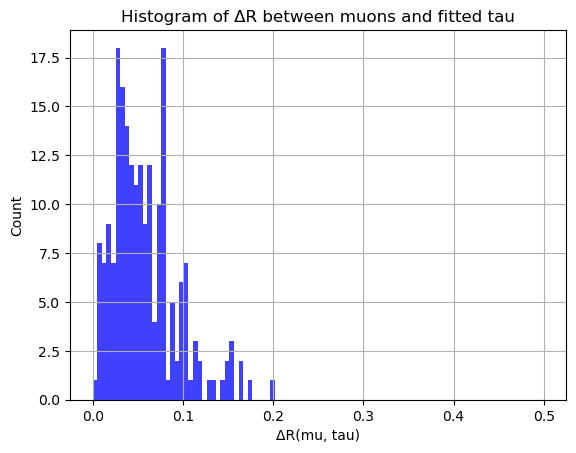

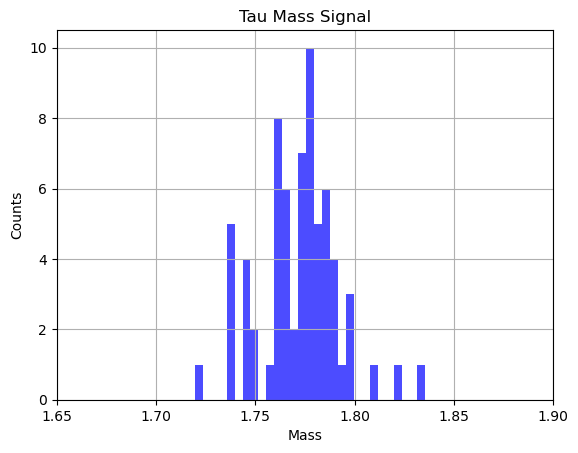

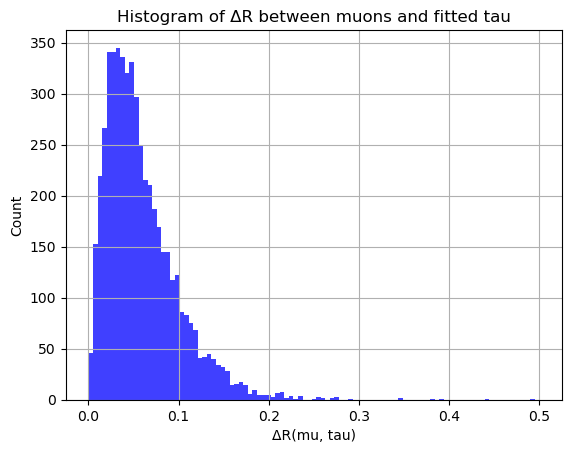

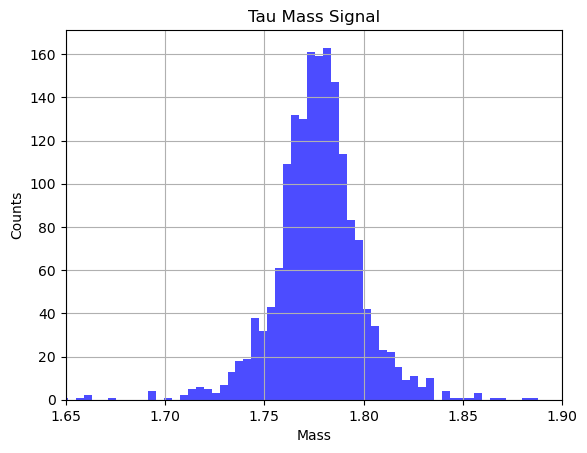

In [17]:
signal_file_path = "data/signal_W/tau3muNANO_mc_05may25v2_1.root"
plot_deltaR_histogram(signal_file_path)
plot_fitted_tau_mass(signal_file_path, "Tau Mass Signal", "Mass", "Counts", xlim=(1.65,1.90), bins=np.linspace(0,2,500))
signal_file_path = "data/signal_W/tau3muNANO_mc_30apr2025v3_1.root"
plot_deltaR_histogram(signal_file_path)
plot_fitted_tau_mass(signal_file_path, "Tau Mass Signal", "Mass", "Counts", xlim=(1.65,1.90), bins=np.linspace(0,2,500))

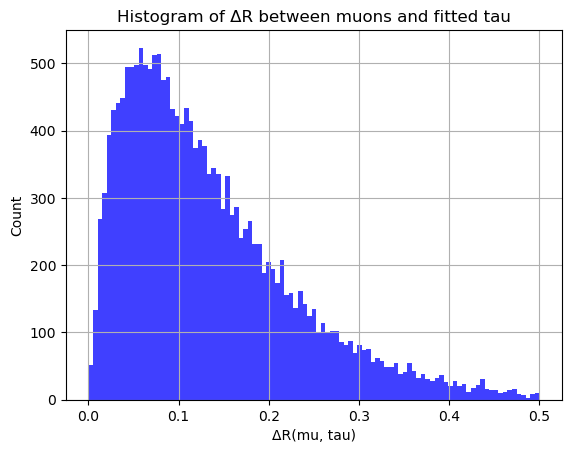

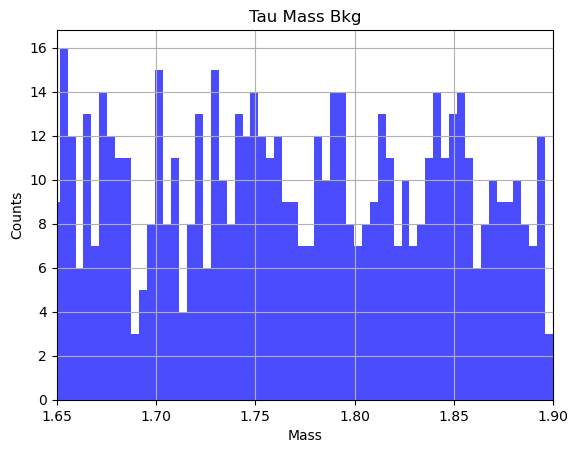

In [6]:
bkg_file_path = "data/background/tau3muNANO_data_30apr2025v1_1.root"
plot_deltaR_histogram(bkg_file_path)
plot_fitted_tau_mass(bkg_file_path, "Tau Mass Bkg", "Mass", "Counts", xlim=(1.65,1.90), bins=np.linspace(0,2,500))

In [7]:
import matplotlib.pyplot as plt

def plot_hist(data, title, xlabel, ylabel, bins=None, xlim=None, ylim=None):
    # Plot histogram
    plt.hist(data, bins=bins, color='green', alpha=0.7)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    if xlim:
        plt.xlim(xlim)
    if ylim: 
        plt.ylim(ylim)
    plt.grid(True)
    plt.show()

1756
5699


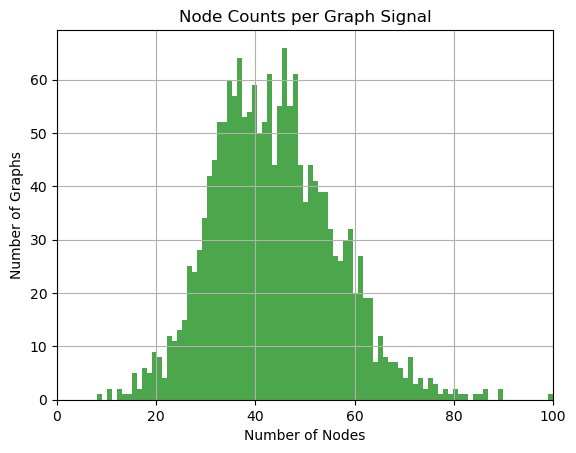

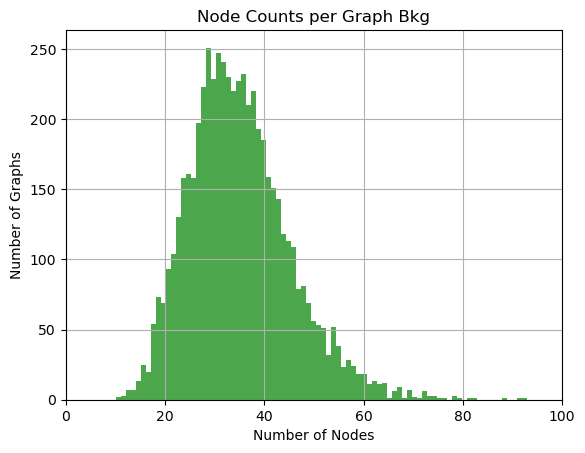

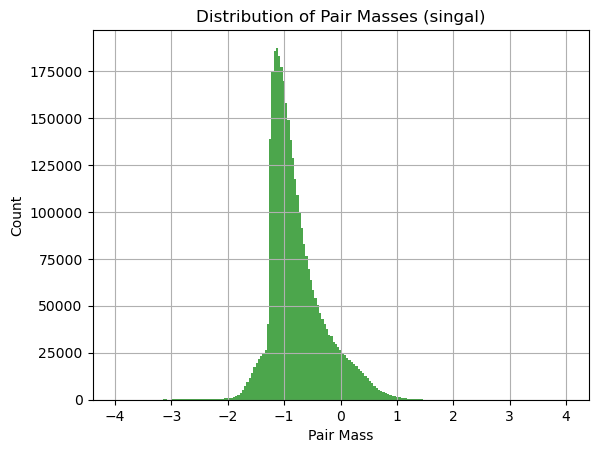

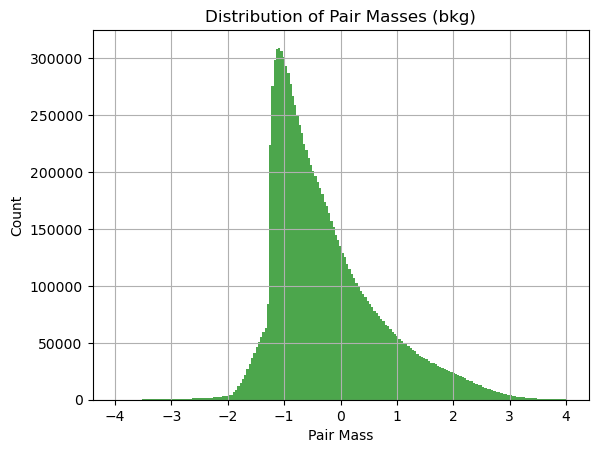

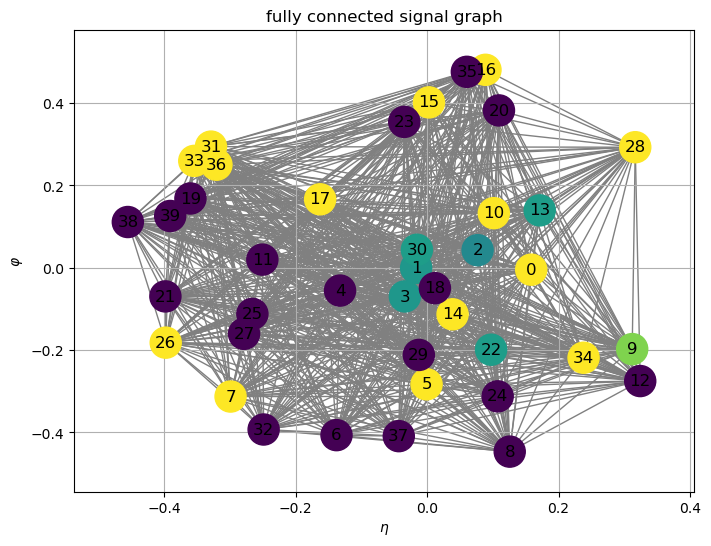

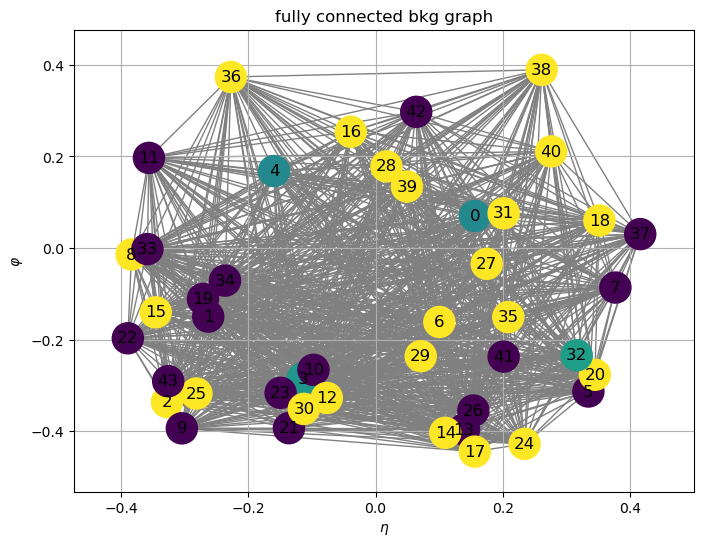

In [15]:
from utils.ConeGraphProducer import ConeGraphProducer
signal_graphs = ConeGraphProducer("data/signal_W", "W_decay_signal_dzd0_cone_size_0.5_fully")
bkg_graphs = ConeGraphProducer("data/background", "background_dzd0_cone_size_0.5_fully")

print(len(signal_graphs))
print(len(bkg_graphs))

num_nodes_per_graph = [data.num_nodes for data in signal_graphs]
plot_hist(num_nodes_per_graph, "Node Counts per Graph Signal", "Number of Nodes", "Number of Graphs", bins=np.linspace(0,100,100), xlim=(0,100))
num_nodes_per_graph = [data.num_nodes for data in bkg_graphs]
plot_hist(num_nodes_per_graph, "Node Counts per Graph Bkg", "Number of Nodes", "Number of Graphs", bins=np.linspace(0,100,100), xlim=(0,100))

pair_masses = [data.edge_attr[:, 0] for data in signal_graphs]  
pair_masses = np.concatenate(pair_masses)
plot_hist(pair_masses, "Distribution of Pair Masses (singal)", "Pair Mass", "Count", bins=np.linspace(-4,4,200))
pair_masses = [data.edge_attr[:, 0] for data in bkg_graphs]  
pair_masses = np.concatenate(pair_masses)
plot_hist(pair_masses, "Distribution of Pair Masses (bkg)", "Pair Mass", "Count", bins=np.linspace(-4,4,200))

plot_graph(signal_graphs[0], "fully connected signal graph")
plot_graph(bkg_graphs[0], "fully connected bkg graph")

In [10]:
f = uproot.open("data/background/tau3muNANO_data_30apr2025v1_1.root")
df = f["Events"]

In [5]:
import pickle

pkl_path = "output/FirstTest_vs2/eval_ROC_AUC.pkl"
with open(pkl_path, "rb") as f:
    auc_data = pickle.load(f)

print(type(auc_data))
print(auc_data["background_dzd0_cone_size_0.5_fully"]['auc'])

<class 'dict'>
0.9462084347120844
